<a href="https://colab.research.google.com/github/mvishrutha/AI-LAB-1BF24CS157-M-Vishrutha-/blob/main/Week_9_resolution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== FOL RESOLUTION PROVER ===
Rules for typing clauses:
  1. Use '~' for NOT   (e.g., ~Allergy(x))
  2. Use '|' for OR    (e.g., ~Allergy(x) | Sneezes(x))
  3. Variables = lowercase (x, y, z)
  4. Constants = Capitalized (Mary, Cat, Alice)

Enter the number of CNF clauses in the Knowledge Base: 4

Enter each CNF clause:
Clause 1: ~Allergy(x) | Sneezes(x)
Clause 2: ~Lives(y, Cat) | ~Allergic(y, Cat) | Allergy(y)
Clause 3: Cat(Tom)
Clause 4: Allergic(Mary, Cat)

Enter the Goal statement to prove (un-negated): Sneezes(Mary)

--- RESOLUTION STEPS ---
Resolved C1 & C2 -> C6: Sneezes(y) ∨ ¬Allergic(y, Cat) ∨ ¬Lives(y, Cat) {'x': 'y'}
Resolved C1 & C5 -> C7: ¬Allergy(Mary) {'x': 'Mary'}
Resolved C2 & C4 -> C8: Allergy(Mary) ∨ ¬Lives(Mary, Cat) {'y': 'Mary'}
Resolved C1 & C8 -> C9: Sneezes(Mary) ∨ ¬Lives(Mary, Cat) {'x': 'Mary'}
Resolved C2 & C7 -> C10: ¬Allergic(Mary, Cat) ∨ ¬Lives(Mary, Cat) {'y': 'Mary'}
Resolved C7 & C8 -> C11: ¬Lives(Mary, Cat)

FAILED: No new clauses can be derived. Empt

/tmp/ipykernel_1504/4129192904.py:224: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


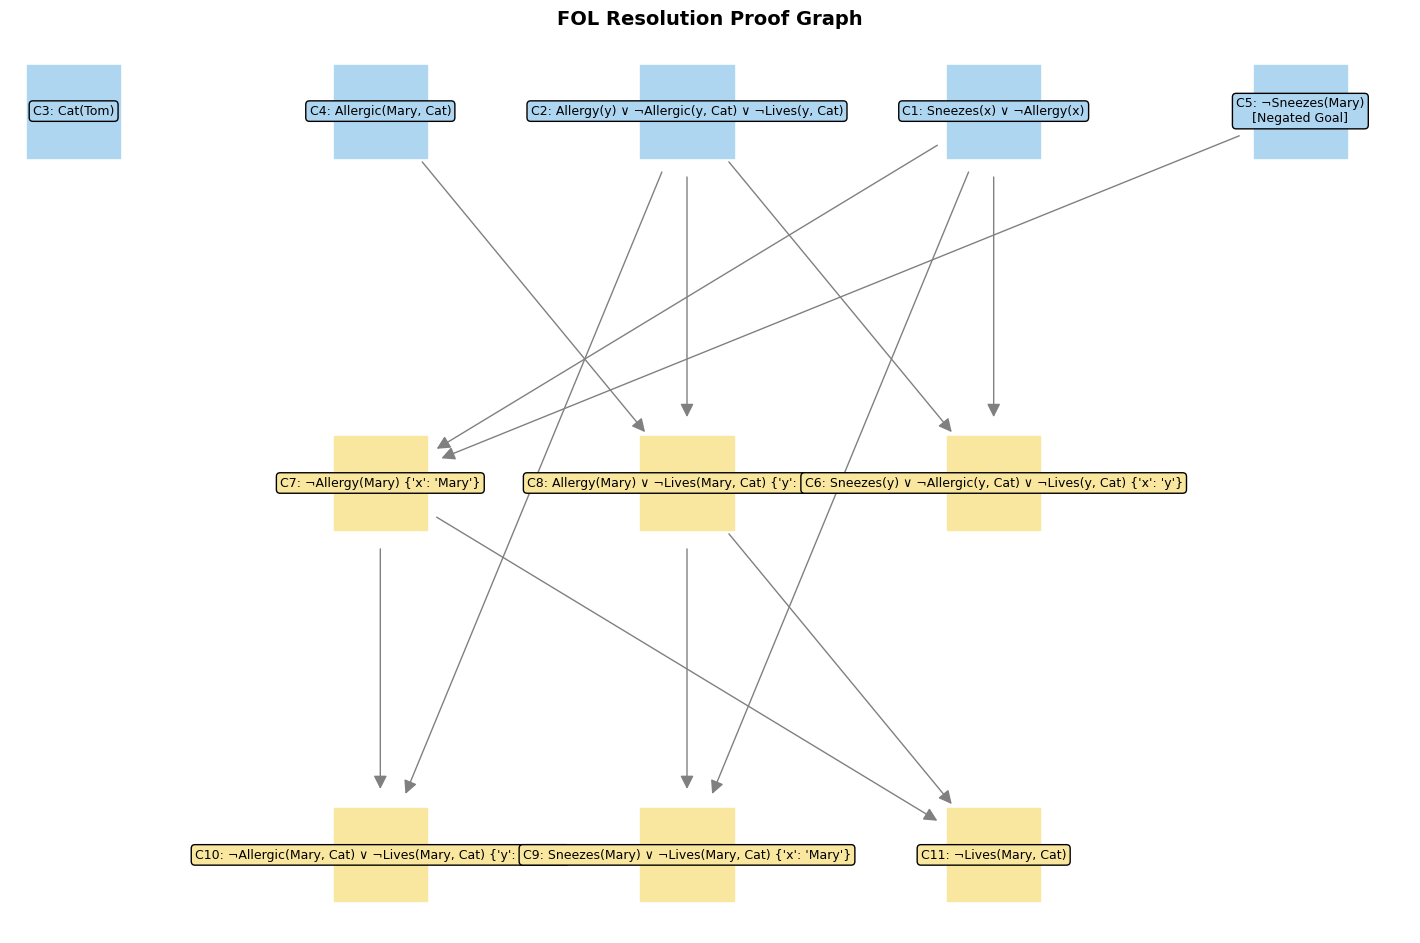

In [3]:
import re
import matplotlib.pyplot as plt
import networkx as nx


# ==========================================
# 1. PARSING & REPRESENTATION
# ==========================================
def parse_literal(lit_str):
    lit_str = lit_str.strip()
    neg = False
    if lit_str.startswith("~") or lit_str.startswith("¬"):
        neg = True
        lit_str = lit_str[1:].strip()
    match = re.match(r"([A-Za-z0-9_]+)\((.*)\)", lit_str)
    if not match:
        raise ValueError(
            f"Invalid literal format: '{lit_str}'. Expected format like Predicate(arg1, arg2)"
        )
    pred = match.group(1)
    args = [a.strip() for a in match.group(2).split(",")]
    return (neg, pred, tuple(args))


def parse_clause(clause_str):
    parts = clause_str.split("|")
    return frozenset(parse_literal(p) for p in parts)


def format_literal(lit):
    neg, pred, args = lit
    prefix = "¬" if neg else ""
    return f"{prefix}{pred}({', '.join(args)})"


def format_clause(clause):
    if not clause:
        return "□ (Empty Clause)"
    return " ∨ ".join(sorted(format_literal(l) for l in clause))


# ==========================================
# 2. UNIFICATION ENGINE
# ==========================================
def is_variable(term):
    # Lowercase = variable (x, y, z); Capitalized = constant (Alice, Mary, Cat)
    return term.islower() and "(" not in term


def unify_var(var, x, theta):
    if var in theta:
        return unify(theta[var], x, theta)
    elif x in theta:
        return unify(var, theta[x], theta)
    else:
        theta[var] = x
        return theta


def unify(x, y, theta):
    if theta is None:
        return None
    elif x == y:
        return theta
    elif isinstance(x, str) and is_variable(x):
        return unify_var(x, y, theta)
    elif isinstance(y, str) and is_variable(y):
        return unify_var(y, x, theta)
    elif isinstance(x, tuple) and isinstance(y, tuple) and len(x) == len(y):
        for a, b in zip(x, y):
            theta = unify(a, b, theta)
        return theta
    else:
        return None


def substitute_clause(clause, theta):
    new_lits = set()
    for neg, pred, args in clause:
        new_args = tuple(theta.get(arg, arg) for arg in args)
        new_lits.add((neg, pred, new_args))
    return frozenset(new_lits)


# ==========================================
# 3. RESOLUTION ENGINE (FIXED)
# ==========================================
def resolve_pair(c1, c2):
    resolvents = []
    for l1 in c1:
        for l2 in c2:
            # Check opposite signs (l1[0] != l2[0]) and same predicate (l1[1] == l2[1])
            if l1[0] != l2[0] and l1[1] == l2[1]:
                theta = unify(l1[2], l2[2], {})
                if theta is not None:
                    new_c1 = substitute_clause(c1 - {l1}, theta)
                    new_c2 = substitute_clause(c2 - {l2}, theta)
                    resolvent = new_c1.union(new_c2)
                    resolvents.append((resolvent, theta))
    return resolvents


def fol_resolution(kb_strings, goal_string):
    clauses = [parse_clause(c) for c in kb_strings]
    goal_clause = parse_clause(goal_string)

    # Negate the goal
    negated_goal = frozenset(
        (not neg, pred, args) for (neg, pred, args) in goal_clause
    )
    clauses.append(negated_goal)

    G = nx.DiGraph()
    clause_to_id = {}
    for idx, c in enumerate(clauses):
        cid = f"C{idx+1}"
        label = f"{cid}: {format_clause(c)}"
        if c == negated_goal:
            label += "\n[Negated Goal]"
        G.add_node(cid, label=label, type="initial")
        clause_to_id[c] = cid

    step_counter = len(clauses) + 1
    derived_list = list(clauses)

    print("\n--- RESOLUTION STEPS ---")
    while True:
        pairs = [
            (derived_list[i], derived_list[j])
            for i in range(len(derived_list))
            for j in range(i + 1, len(derived_list))
        ]
        added_new = False

        for c1, c2 in pairs:
            for resolvent, theta in resolve_pair(c1, c2):
                if resolvent not in clause_to_id:
                    cid = f"C{step_counter}"
                    step_counter += 1
                    sub_str = f" {theta}" if theta else ""
                    label = f"{cid}: {format_clause(resolvent)}{sub_str}"

                    node_type = "empty" if len(resolvent) == 0 else "derived"
                    G.add_node(cid, label=label, type=node_type)
                    G.add_edge(clause_to_id[c1], cid)
                    G.add_edge(clause_to_id[c2], cid)

                    clause_to_id[resolvent] = cid
                    derived_list.append(resolvent)
                    added_new = True

                    print(
                        f"Resolved {clause_to_id[c1]} & {clause_to_id[c2]} -> {label}"
                    )

                    if len(resolvent) == 0:
                        print(
                            "\nSUCCESS: Empty clause (□) derived! Goal is PROVED."
                        )
                        return True, G

        if not added_new:
            print(
                "\nFAILED: No new clauses can be derived. Empty clause (□) NOT reached."
            )
            return False, G


# ==========================================
# 4. GRAPH VISUALIZATION
# ==========================================
def draw_resolution_graph(G, title="FOL Resolution Proof Graph"):
    plt.figure(figsize=(14, 9))

    for layer, nodes in enumerate(nx.topological_generations(G)):
        for node in nodes:
            G.nodes[node]["layer"] = layer

    pos = nx.multipartite_layout(G, subset_key="layer", align="horizontal")
    # Flip Y-axis so initial clauses appear at the top and conclusion at the bottom
    pos = {k: (v[0], -v[1]) for k, v in pos.items()}

    colors = []
    for node in G.nodes():
        ntype = G.nodes[node]["type"]
        if ntype == "initial":
            colors.append("#AED6F1")  # Light Blue
        elif ntype == "empty":
            colors.append("#82E0AA")  # Green (Success)
        else:
            colors.append("#F9E79F")  # Yellow (Derived)

    labels = nx.get_node_attributes(G, "label")

    nx.draw(
        G,
        pos,
        with_labels=False,
        node_color=colors,
        node_size=4500,
        node_shape="s",
        edge_color="gray",
        arrows=True,
        arrowsize=20,
    )

    for node, (x, y) in pos.items():
        plt.text(
            x,
            y,
            labels[node],
            fontsize=9,
            ha="center",
            va="center",
            bbox=dict(
                boxstyle="round,pad=0.3",
                fc=colors[list(G.nodes()).index(node)],
                ec="black",
            ),
        )

    plt.title(title, fontsize=14, fontweight="bold")
    plt.axis("off")
    plt.tight_layout()
    plt.show()


# ==========================================
# 5. INTERACTIVE USER INPUT
# ==========================================
if __name__ == "__main__":
    print("=== FOL RESOLUTION PROVER ===")
    print("Rules for typing clauses:")
    print("  1. Use '~' for NOT   (e.g., ~Allergy(x))")
    print("  2. Use '|' for OR    (e.g., ~Allergy(x) | Sneezes(x))")
    print("  3. Variables = lowercase (x, y, z)")
    print("  4. Constants = Capitalized (Mary, Cat, Alice)\n")

    n = int(input("Enter the number of CNF clauses in the Knowledge Base: "))
    kb = []

    print("\nEnter each CNF clause:")
    for i in range(n):
        clause = input(f"Clause {i+1}: ").strip()
        kb.append(clause)

    goal = input("\nEnter the Goal statement to prove (un-negated): ").strip()

    proved, graph = fol_resolution(kb, goal)
    draw_resolution_graph(graph, title="FOL Resolution Proof Graph")
